In [1]:
import joblib
import pandas as pd
import shap
import numpy as np

In [5]:
save_dir = "../29-08-26-Ravi/model"

# Load model
xgb_model = joblib.load(f"{save_dir}/xgboost_model.pkl")

# Load datasets
X_train = pd.read_parquet(f"{save_dir}/X_train.parquet")
X_test = pd.read_parquet(f"{save_dir}/X_test.parquet")
X_val = pd.read_parquet(f"{save_dir}/X_val.parquet")
y_train = pd.read_parquet(f"{save_dir}/y_train.parquet").squeeze()
y_test = pd.read_parquet(f"{save_dir}/y_test.parquet").squeeze()
y_val = pd.read_parquet(f"{save_dir}/y_val.parquet").squeeze()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("X_test :", X_val.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("y_test :", y_val.shape)

X_train: (275334, 20)
X_test : (59001, 20)
X_test : (59000, 20)
y_train: (275334,)
y_test : (59001,)
y_test : (59000,)


### Use a small representative background and a separate sample for explanation.

In [6]:
# Background sample

background_size = 500
background = X_train.sample(n=background_size,random_state=42)

In [7]:
# SHAP explainer
explainer = shap.TreeExplainer(xgb_model,data=background)

In [8]:
# Rows to explain

X_shap = X_test.sample(n=min(5000, len(X_test)),random_state=42)

In [9]:
# Calculate SHAP values

shap_values = explainer.shap_values(X_shap)

print("X_shap:", X_shap.shape)
print("SHAP:", np.asarray(shap_values).shape)

100%|===================| 4986/5000 [01:08<00:00]        

X_shap: (5000, 20)
SHAP: (5000, 20)


In [12]:
import xgboost
print("SHAP:", shap.__version__)
print("XGBoost:", xgboost.__version__)

SHAP: 0.51.0
XGBoost: 3.2.0


### By using the shap.kmeans

In [14]:
'''
background = shap.kmeans(X_train,50)
explainer = shap.TreeExplainer(xgb_model,data=background)
X_shap = X_test.sample(n=5000,random_state=42)
shap_values = explainer.shap_values(X_shap)

'''

'\nbackground = shap.kmeans(X_train,50)\nexplainer = shap.TreeExplainer(xgb_model,data=background)\nX_shap = X_test.sample(n=5000,random_state=42)\nshap_values = explainer.shap_values(X_shap)\n\n'

- Using shap.kmeans is opted for error .
- So I am using random sampling
- it is far more better than sha.kmeans

### Generate your SHAP summary plot

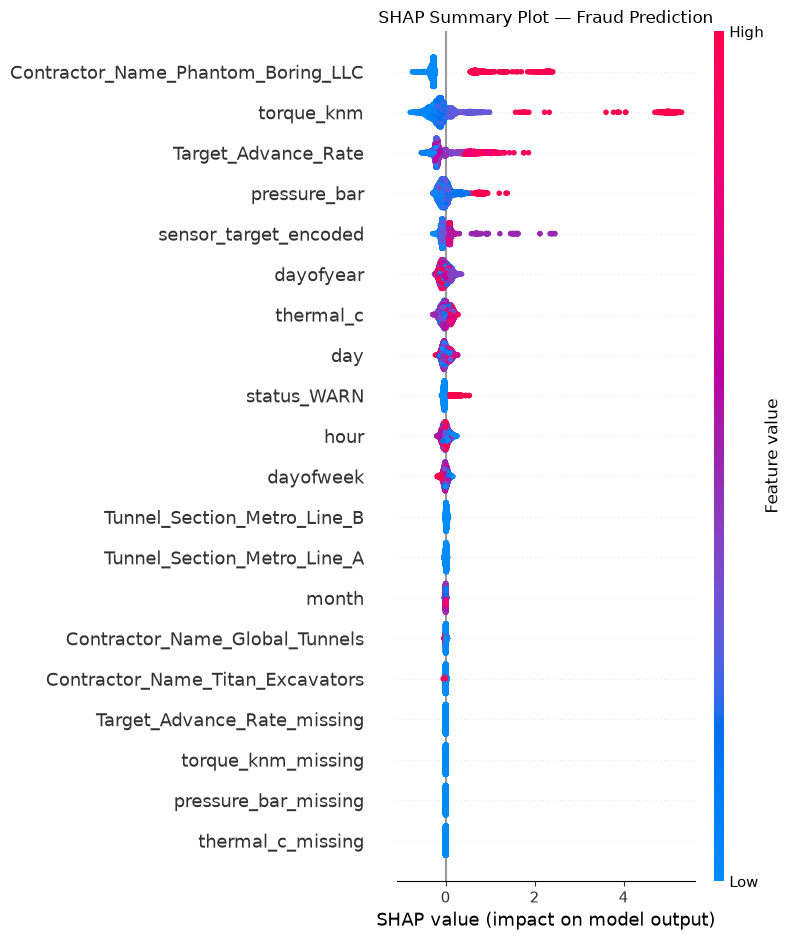

In [15]:
import matplotlib.pyplot as plt

shap.summary_plot(shap_values,X_shap,show=False)
plt.title("SHAP Summary Plot — Fraud Prediction")
plt.tight_layout()
plt.show()

### specific hypothesis low thermal_c + high torque_knm → fraud

- calculate interaction SHAP values:

In [16]:
X_interaction = X_test.sample(n=2000, random_state=42)
interaction_values = explainer.shap_interaction_values(X_interaction)

In [17]:
thermal_idx = X_interaction.columns.get_loc("thermal_c")
torque_idx = X_interaction.columns.get_loc("torque_knm")

interaction_strength = np.mean(np.abs(interaction_values[:,thermal_idx,torque_idx]))
print("thermal_c × torque_knm interaction:",interaction_strength)

thermal_c × torque_knm interaction: 0.0


- It means your current SHAP interaction calculation does not show a meaningful thermal_c × torque_knm interaction. So we should not claim that "low thermal_c + high torque_knm" is the #1 fraud indicator based on this result.

### So, First check the individual SHAP importance

In [18]:
importance = pd.DataFrame({
                         "feature": X_shap.columns,
                        "mean_abs_shap": np.abs(shap_values).mean(axis=0)}).sort_values("mean_abs_shap",ascending=False)
print(importance.head(20))

                               feature  mean_abs_shap
16  Contractor_Name_Phantom_Boring_LLC       0.475805
1                           torque_knm       0.436266
0                  Target_Advance_Rate       0.315261
2                         pressure_bar       0.126326
19               sensor_target_encoded       0.103447
11                           dayofyear       0.085256
3                            thermal_c       0.081177
12                                 day       0.065082
18                         status_WARN       0.059059
8                                 hour       0.055668
9                            dayofweek       0.037998
14         Tunnel_Section_Metro_Line_B       0.016174
13         Tunnel_Section_Metro_Line_A       0.012679
10                               month       0.005144
15      Contractor_Name_Global_Tunnels       0.004288
17    Contractor_Name_Titan_Excavators       0.003803
4          Target_Advance_Rate_missing       0.000000
5                   torque_k

In [19]:
print(importance[importance["feature"].isin(["thermal_c", "torque_knm"])])

      feature  mean_abs_shap
1  torque_knm       0.436266
3   thermal_c       0.081177


- So your model is strongly dependent on torque_knm, while thermal_c has a smaller but still meaningful contribution.
- The ratio is about 5.37×:
- #### 0.436266 / 0.081177 ≈ 5.37
- It is means torque_knm is the ##### 1 individual predictor, and thermal_c is ###### 2.
- But we do not yet have evidence that low thermal_c combined with high torque_knm is the logic trap.
- That's actually a very important distinction for our Chief Engineer

#### Now let's test the direction

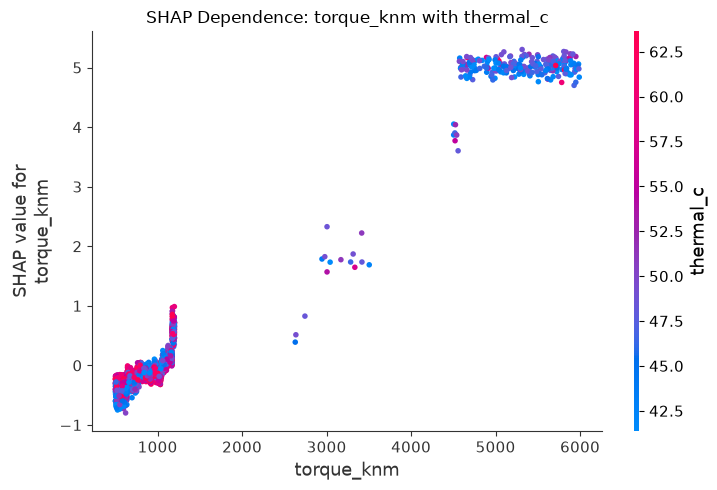

In [20]:
shap.dependence_plot("torque_knm",shap_values,X_shap,interaction_index="thermal_c",show=False)
plt.title("SHAP Dependence: torque_knm with thermal_c")
plt.tight_layout()
plt.show()

#### conclusion:- 
- torque_knm is the dominant model driver. Its mean absolute SHAP value is 0.4363, compared with 0.0812 for thermal_c—about 5.37× larger.
- The torque_knm effect is strongly non-linear. The step-like SHAP pattern indicates that the XGBoost model has learned specific torque regimes rather than a simple linear relationship.
- At 4,500–6,000 torque_knm, the SHAP contribution reaches roughly +5, meaning these observations strongly push the model toward the positive/fraud class.
- thermal_c does not appear to materially modify the torque effect. The uniform color distribution and the measured interaction of 0.0 support this.
- Therefore, the evidence does not support the claim that "low thermal_c + high torque_knm is the #1 fraud indicator."
- The evidence instead supports a stronger statement: high torque_knm alone is the primary learned indicator of fraud in the current XGBoost model.

In [21]:
# Make sure JavaScript support is initialized
shap.initjs()

# Force plot for prediction #0
force_plot = shap.force_plot(explainer.expected_value,shap_values[0],X_shap.iloc[0],matplotlib=False)

# Export as interactive HTML
shap.save_html(f"{save_dir}/shap_force_plot_prediction_0.html",force_plot)
print("Saved: shap_force_plot_prediction_0.html")

Saved: shap_force_plot_prediction_0.html


#### #1 to 30 force plot of fraud prediction.

In [23]:
def save_plot(n, save_dir):
    shap.initjs()
    for i in range(n):
        force_plot = shap.force_plot(explainer.expected_value,shap_values[i],X_shap.iloc[i],matplotlib=False)
        # Export as interactive HTML
        shap.save_html(f"{save_dir}/result/shap_force_plot_prediction_{i}.html",force_plot)
    return print(f"Saved: shap_force_plot_prediction_{i}.html")
    
    

In [24]:
save_plot(n=30,save_dir=save_dir)

Saved: shap_force_plot_prediction_{i}.html
